In [1]:
source('../../R/preamble.R')

small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

pure = c('A','B','C','D','F')


In [2]:
# Time between reagent addition and recording
delays = data.frame(day = 0:3, delay = c(10,10,8,11))

d =
    read.tsv('../../datasets/stationary_survival/ss_beta_full.txt') %>% 
    pivot_longer(-c(day, point), names_to = 'well', values_to = 'lum') %>%
    left_join(delays) %>% 
    mutate(
        strain = substr(well, 1, 1), strain = case_when(strain == 'E' ~ 'WT', strain == 'H' ~ 'ATP', T ~ strain),
        rep = substr(well, 2, 3),
        pt = point + delay
        ) %>%
    filter(well != 'blank')

Joining with `by = join_by(day)`


### How long does it take for luminescence to reach the plateau
The ATP standard plateaus around 10 min at most. The signal for the cultures decays super fast.

Warning message:
“The `scale_name` argument of `discrete_scale()` is deprecated as of ggplot2
3.5.0.”


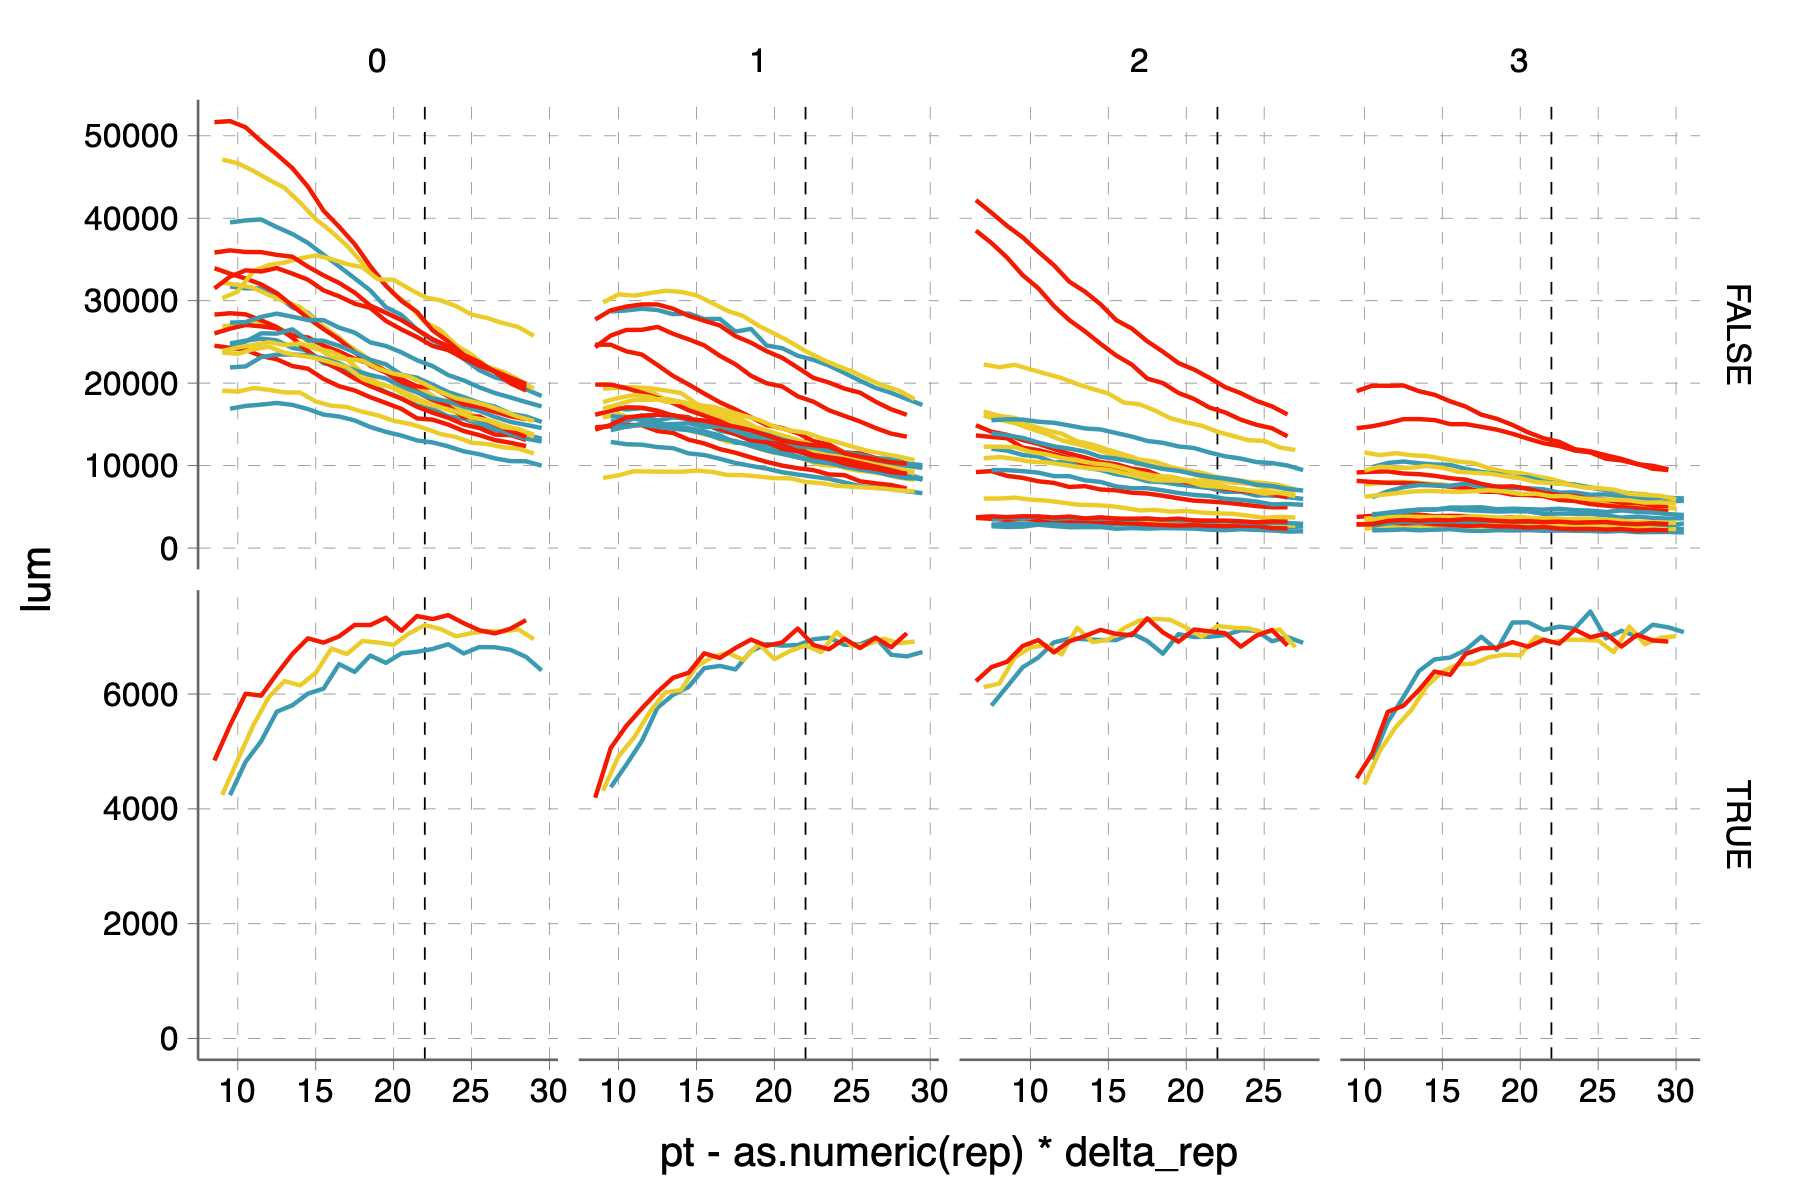

In [3]:
size(4, 6)

# When ATP is stabilized
measurement_point = 22 # min, when to measure after addition of reagent
delta_rep = 0.5 # pipetting took 30s between each replicates

d %>% 

ggplot() + aes(pt - as.numeric(rep) * delta_rep, lum, col = rep, group = paste(day, strain, rep)) + 
    nl +
    ylim(0, NA) +
    facet_grid(strain == 'ATP' ~ day, scale = 'free') +
    geom_vline(xintercept = measurement_point, lwd = 0.2, lty = 2) +
    geom_line()

In [4]:
d_norm = d %>%

    # Pick a time after ATP is equilibrated and the cultures are lysed (shouldn't affect the results much)
    group_by(day, strain, rep) %>% 
    summarise(lum = approx(x = pt - as.numeric(rep) * delta_rep, y = lum, xout = measurement_point)$y) %>% 

    # normalize wrt ATP
    group_by(day, rep) %>% 
    mutate(lum_norm = lum / lum[strain == 'ATP']) %>% 
    filter(strain != 'ATP') %>% 

    # normalize wrt Day 0
    group_by(strain, rep) %>% 
    mutate(lum_rel = lum / lum[day == 0]) %>%
    ungroup()

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by day, strain, and rep.
ℹ Output is grouped by day and strain.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(day, strain, rep))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


### By strain

## Error-bar version

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by day and strain.
ℹ Output is grouped by day.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(day, strain))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


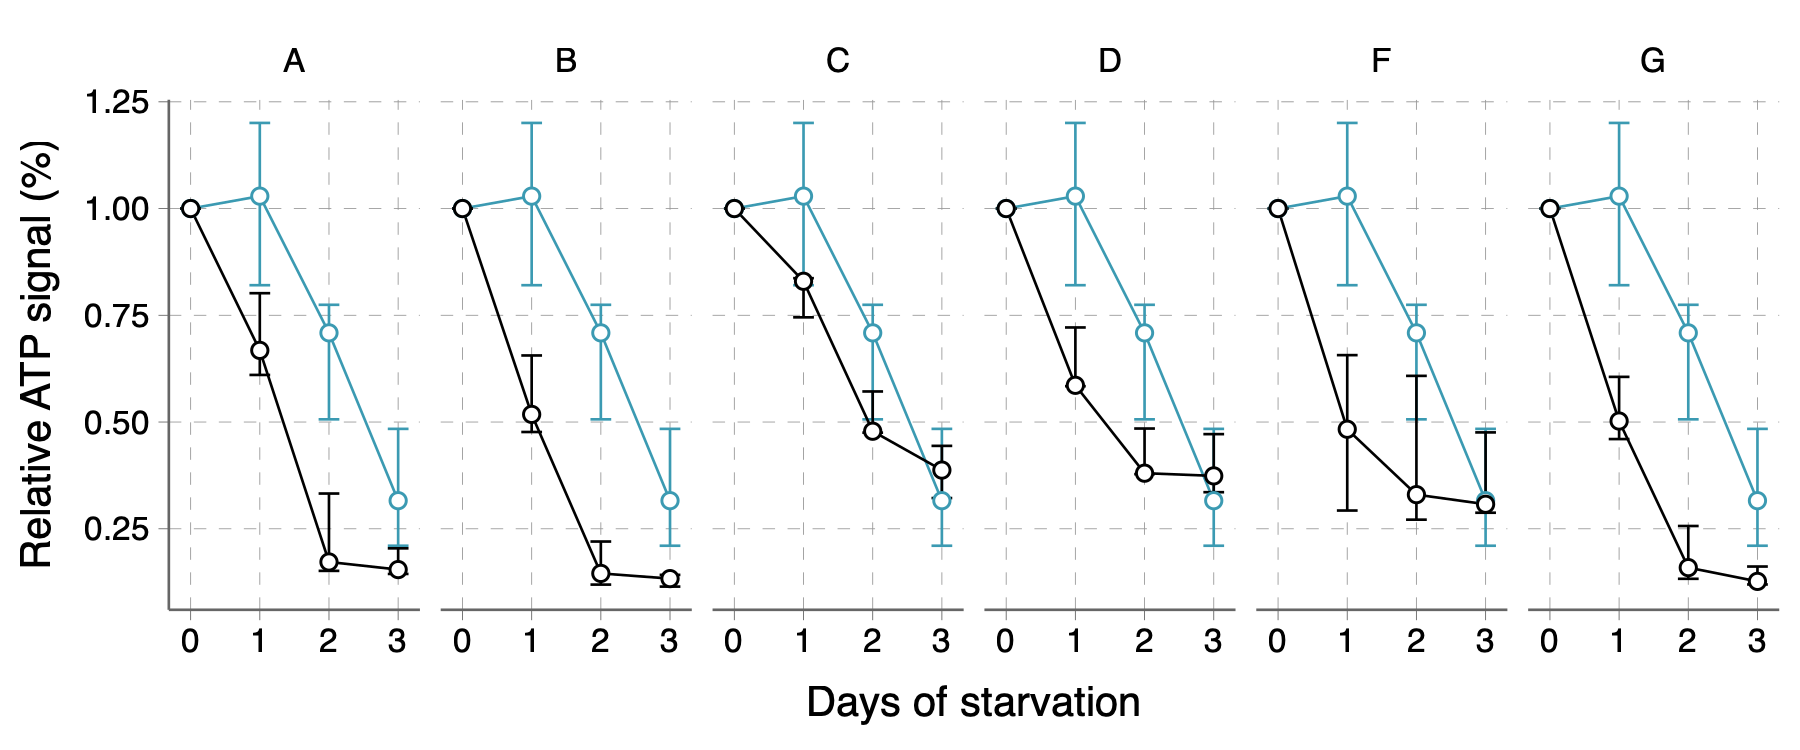

In [5]:
size(2.5, 6)
contrast = b

d_sum =
d_norm %>%
    group_by(day, strain) %>%
    summarise(
        mm = median(lum_rel), mn = min(lum_rel), mx = max(lum_rel)
        ) %>%
    ungroup()

wt_data = d_sum %>% filter(strain == 'WT') %>% select(-strain)
wt_color = pal[1]

d_sum %>% filter(strain != 'WT') %>% 

ggplot() + aes(day, mm, 
               ymin = mn, ymax = mx
               ) + 

    facet_grid(~strain) +

    #geom_ribbon(data = wt_data, alpha = 0.1, col = NA, fill = wt_color) +
    geom_line(data = wt_data, lwd = 0.3, col = wt_color, lty = 1) +
    geom_errorbar(data = wt_data, width = 0.3, lwd = 0.3, col = wt_color) +

    #geom_ribbon(alpha = 0.1, col = NA, fill = contrast) +
    geom_line(lwd = 0.3, col = contrast) + 
    geom_errorbar(width = 0.3, lwd = 0.3, col = contrast) +

    geom_point(data = wt_data, pch = 21, fill = w, col = wt_color) +
    geom_point(pch = 21, fill = w, col = contrast) +
    
    labs(x = 'Days of starvation', y = 'Relative ATP signal (%)')

psave('survival_by_population')

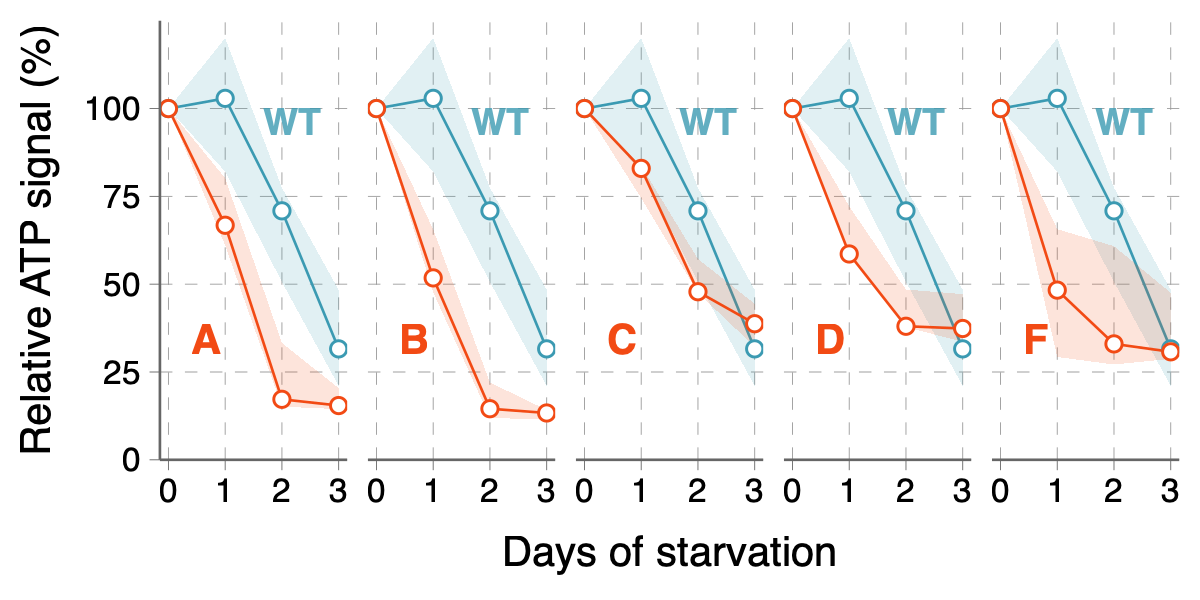

In [6]:
size(2, 5)
ribbon_alpha = 0.15
ribbon_lwd = 0
point_size = 1.5

wt_color = pal[1]
contrast = 'grey40'
dark_red = '#F24A14' #'#f29232'
contrast = dark_red

label_size = 3.5
pure = c('A','B','C','D','F')

ev_letters = data.frame(strain = pure, day = 0.4, mm = 0.3, mn = NA, mx = NA)
wt_letters = data.frame(day = 2.7, mm = 1, mn = NA, mx = NA)

survival_by_population_ribbon_one_row =
d_sum %>% filter(strain %in% pure) %>% 

ggplot() + aes(day, mm * 100, ymin = mn * 100, ymax = mx * 100
               ) + 

    facet_wrap(~strain, ncol = 6) +
    ycont(0, 125, breaks = seq(0, 100, 25)) +

    geom_ribbon(data = wt_data, alpha = ribbon_alpha, col = wt_color, fill = wt_color, lwd = ribbon_lwd) +
    geom_line(data = wt_data, lwd = 0.3, col = wt_color, lty = 1) +
    #geom_errorbar(data = wt_data, width = 0.3, lwd = 0.3, col = wt_color) +

    geom_ribbon(alpha = ribbon_alpha, col = contrast, fill = contrast, lwd = ribbon_lwd) +
    geom_line(lwd = 0.3, col = contrast) + 
    #geom_errorbar(width = 0.3, lwd = 0.3, col = contrast) +

    geom_point(data = wt_data, size = point_size, pch = 21, fill = w, col = wt_color) +
    geom_point(pch = 21, size = point_size, fill = w, col = contrast) +
    
    geom_text(
        aes(label = strain),
        data = ev_letters,
        vjust = 0, hjust = 0, fontface = 'bold', size = label_size, col = contrast
        ) +        
    geom_text(
        aes(label = 'WT'),
        data = wt_letters,
        fontface = 'bold', 
        vjust = 1, hjust = 1, size = label_size*0.9, col = wt_color, alpha = 0.8
        ) +

    theme(strip.text = eb) + small_text + small_titles +

    labs(x = 'Days of starvation', y = 'Relative ATP signal (%)')

size(2, 4)
survival_by_population_ribbon_one_row
psave('survival_by_population_ribbon_one_row')

# Survival vs mutation rate

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain and rep.
ℹ Output is grouped by strain.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, rep))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


Joining with `by = join_by(strain)`


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by strain and n_mut.
ℹ Output is grouped by strain.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(strain, n_mut))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


[1] 5


[1] 0.765617


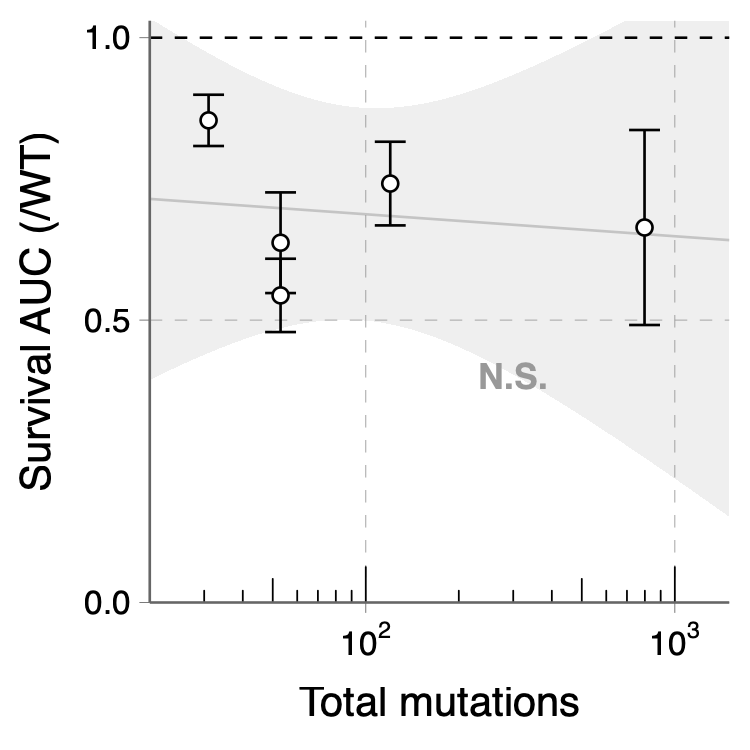

In [7]:
d = read.tsv('../../datasets/genomics/04_gene_attribution/results/d_labeled.tsv')

strain_to_n_mut = d %>%
    filter(gen == 24, freq > 0.95) %>% 
    #filter(cat=='synonymous') %>%
    group_by(pop) %>%
    summarise(n_mut = n()) %>% 
    rename(strain=pop) %>% 
    add_row(strain='WT', n_mut=0)

lwd = 0.3
xmin = 2e1
xmax = 1.5e3
contrast = 'grey60'

df =
d_norm %>%
    # Area under the relative signal curve (trapezoidal rule, days 0-3)
    arrange(strain, rep, day) %>% 
    group_by(strain, rep) %>%
    summarise(auc = sum(diff(day) * (head(lum_rel, -1) + tail(lum_rel, -1)) / 2)) %>%
    ungroup() %>% 
    mutate(auc_wt = mean(auc[strain=='WT'])) %>% 
    filter(strain %in% pure) %>% # same lineages as the survival curves

    left_join(strain_to_n_mut) %>% 
    ungroup() %>% 
    mutate(
        log_n_mut = log10(n_mut),
        rauc = auc / auc_wt
    )

summary_df =
    df %>% 
    group_by(strain, n_mut) %>%
    summarise(m = mean(rauc), s = sd(rauc)) %>%
    ungroup()

# Linear reg on lineage means (replicates are not independent lineages)
lineage_df = df %>% group_by(strain, log_n_mut) %>% summarise(rauc = mean(rauc), .groups = 'drop')
model = lm(rauc ~ log_n_mut, data = lineage_df)

# Get predictions and confidence intervals
pred_df = data.frame(log_n_mut = seq(log10(xmin), log10(xmax), length.out = 100))
pred_df = cbind(pred_df, predict(model, newdata = pred_df, interval = "confidence"))

# Get p-value
p_value = summary(model)$coefficients["log_n_mut", "Pr(>|t|)"]
print(nrow(lineage_df)); print(p_value)

size(2.5, 2.5)

ggplot() + 

    ycont(0, 1.03, breaks=seq(0, 1, 0.5), oob=scales::oob_squish) + # squish keeps the CI band when it exceeds the axis +
    xlog(xmin, xmax, breaks=c(1e2,1e3)) + logticks('b') +

    # Regression
    geom_ribbon(data = pred_df, aes(x=10^log_n_mut, min = lwr, max = upr), fill = contrast, alpha = 0.15) +
    geom_line(
        data = pred_df, aes(x=10^log_n_mut, y = fit), 
        color = contrast, lwd = lwd, alpha = 0.5
    ) +
    geom_hline(yintercept = 1, lty=2, lwd=lwd) +
    add_text(
        3e2, 0.4, 'N.S.',
        col = contrast, size = 3, fontface = 'bold'
    ) +

    # Data
    geom_errorbar(
        data = summary_df,
        aes(n_mut, m, min=m-s, max=m+s),
        lwd = lwd, width = 0.1
    ) +
    geom_point(
        data = summary_df,
        aes(n_mut, m),
        pch = 21, size = 1.5, fill = w, stroke = lwd*1.5
    ) +

    small_titles + small_text +
    labs(x = 'Total mutations', y = 'Survival AUC (/WT)')

saveRDS(last_plot(), 'GG/survival_auc_vs_mutations.rds')